In [35]:
import pandas as pd
import requests
import statsmodels as sm
import numpy as np
import matplotlib as plt
import seaborn as sns
import urllib3
import csv
import time
from scipy import io
import importlib

urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

In [36]:
DataFrame_incidenti = pd.read_csv('DataFrame_incidenti', na_values=['', 'NaN', 'null'], keep_default_na=False)
DataFrame_incidenti.isna().sum()

Unnamed: 0                 0
NOME_COMUNE                0
TIPO_COMUNE                0
CODICE_AREA                0
CODICE_REGIONE             0
ANNO                       0
SUPERFICIE_KMQ             0
POPOLAZIONE                0
RIPARTIZIONE_GEOGRAFICA    0
TIPO_INCIDENTE             0
RISULTATO_INCIDENTE        0
NUMERO_INCIDENTI           0
ZONA_ALTIMETRICA           0
ALTITUDINE_m               0
PRESENZA_MONTAGNE          0
COMUNE_LITORANEO           0
dtype: int64

# Raggruppo i dati per comune, anno e categoria per evitare doppioni, sommo il totale degli incidenti e prendo il valore massimo per la popolazione e la superficie territoriale.


In [105]:
df_intermedio = DataFrame_incidenti.groupby(
    ['NOME_COMUNE', 'ANNO', 'CODICE_REGIONE', 'TIPO_COMUNE', 'RIPARTIZIONE_GEOGRAFICA', 'ZONA_ALTIMETRICA', 'ALTITUDINE_m', 'RISULTATO_INCIDENTE', 'PRESENZA_MONTAGNE', 'COMUNE_LITORANEO']
).agg({
    'NUMERO_INCIDENTI': 'sum',
    'POPOLAZIONE': 'max',
    'SUPERFICIE_KMQ': 'max'
}).reset_index()
df_intermedio

,NOME_COMUNE,ANNO,CODICE_REGIONE,TIPO_COMUNE,RIPARTIZIONE_GEOGRAFICA,ZONA_ALTIMETRICA,ALTITUDINE_m,RISULTATO_INCIDENTE,PRESENZA_MONTAGNE,COMUNE_LITORANEO,NUMERO_INCIDENTI,POPOLAZIONE,SUPERFICIE_KMQ
0,Abano Terme,2010,VENETO,Provincia,Nord-est,pianura,14.0,EVENTI,NON MONTANO,NON LITORANEO,80,19349.0,21.41
1,Abano Terme,2010,VENETO,Provincia,Nord-est,pianura,14.0,FERITI,NON MONTANO,NON LITORANEO,101,19349.0,21.41
2,Abano Terme,2010,VENETO,Provincia,Nord-est,pianura,14.0,MORTI,NON MONTANO,NON LITORANEO,0,19349.0,21.41
3,Abano Terme,2011,VENETO,Provincia,Nord-est,pianura,14.0,EVENTI,NON MONTANO,NON LITORANEO,60,19349.0,21.41
4,Abano Terme,2011,VENETO,Provincia,Nord-est,pianura,14.0,FERITI,NON MONTANO,NON LITORANEO,74,19349.0,21.41
...,...,...,...,...,...,...,...,...,...,...,...,...,...
339112,Zungri,2023,CALABRIA,Provincia,Sud,collina interna,554.0,FERITI,NON MONTANO,NON LITORANEO,1,1985.0,23.46
339113,Zungri,2023,CALABRIA,Provincia,Sud,collina interna,554.0,MORTI,NON MONTANO,NON LITORANEO,0,1985.0,23.46
339114,Zungri,2024,CALABRIA,Provincia,Sud,collina interna,554.0,EVENTI,NON MONTANO,NON LITORANEO,3,1985.0,23.46
339115,Zungri,2024,CALABRIA,Provincia,Sud,collina interna,554.0,FERITI,NON MONTANO,NON LITORANEO,5,1985.0,23.46


Trasformiamo le righe in colonne affiancate (Eventi, Feriti, Morti)


In [106]:
incidenti_agg = df_intermedio.pivot_table(
    index=['NOME_COMUNE', 'ANNO', 'CODICE_REGIONE', 'TIPO_COMUNE', 'RIPARTIZIONE_GEOGRAFICA', 'ZONA_ALTIMETRICA', 'POPOLAZIONE', 'SUPERFICIE_KMQ', 'ALTITUDINE_m', 'PRESENZA_MONTAGNE', 'COMUNE_LITORANEO'],
    columns='RISULTATO_INCIDENTE',
    values='NUMERO_INCIDENTI',
    aggfunc='sum'
).reset_index()

In [107]:
# Calcoliamo i nostri indicatori chiave sul totale degli eventi
incidenti_agg['ACC_KMQ'] = incidenti_agg['EVENTI'] / incidenti_agg['SUPERFICIE_KMQ']
incidenti_agg['ACC_RATE'] = (incidenti_agg['EVENTI'] / incidenti_agg['POPOLAZIONE']) * 1000

# qui semplicemente elimino il nome della colonna "RISULTATO_INCIDENTE" che si può vedere come prima colonna, è causato dal pivot del dataframe
incidenti_agg.columns.name = None

incidenti_agg

,NOME_COMUNE,ANNO,CODICE_REGIONE,TIPO_COMUNE,RIPARTIZIONE_GEOGRAFICA,ZONA_ALTIMETRICA,POPOLAZIONE,SUPERFICIE_KMQ,ALTITUDINE_m,PRESENZA_MONTAGNE,COMUNE_LITORANEO,EVENTI,FERITI,MORTI,ACC_KMQ,ACC_RATE
0,Abano Terme,2010,VENETO,Provincia,Nord-est,pianura,19349.0,21.41,14.0,NON MONTANO,NON LITORANEO,80,101,0,3.736572,4.134581
1,Abano Terme,2011,VENETO,Provincia,Nord-est,pianura,19349.0,21.41,14.0,NON MONTANO,NON LITORANEO,60,74,1,2.802429,3.100935
2,Abano Terme,2012,VENETO,Provincia,Nord-est,pianura,19349.0,21.41,14.0,NON MONTANO,NON LITORANEO,30,36,0,1.401214,1.550468
3,Abano Terme,2013,VENETO,Provincia,Nord-est,pianura,19349.0,21.41,14.0,NON MONTANO,NON LITORANEO,64,82,2,2.989257,3.307664
4,Abano Terme,2014,VENETO,Provincia,Nord-est,pianura,19349.0,21.41,14.0,NON MONTANO,NON LITORANEO,67,80,1,3.129379,3.462711
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113034,Zungri,2020,CALABRIA,Provincia,Sud,collina interna,1985.0,23.46,554.0,NON MONTANO,NON LITORANEO,1,2,0,0.042626,0.503778
113035,Zungri,2021,CALABRIA,Provincia,Sud,collina interna,1985.0,23.46,554.0,NON MONTANO,NON LITORANEO,1,1,0,0.042626,0.503778
113036,Zungri,2022,CALABRIA,Provincia,Sud,collina interna,1985.0,23.46,554.0,NON MONTANO,NON LITORANEO,1,2,0,0.042626,0.503778
113037,Zungri,2023,CALABRIA,Provincia,Sud,collina interna,1985.0,23.46,554.0,NON MONTANO,NON LITORANEO,1,1,0,0.042626,0.503778


In [108]:
incidenti_agg.describe()

,ANNO,POPOLAZIONE,SUPERFICIE_KMQ,ALTITUDINE_m,EVENTI,FERITI,MORTI,ACC_KMQ,ACC_RATE
count,113039.000000,1.130390e+05,113039.000000,113039.000000,113039.000000,113039.000000,113039.000000,113039.000000,113039.000000
mean,2016.912216,7.728051e+03,37.403746,353.446793,22.844593,31.865250,0.429082,0.674095,1.786194
std,4.270569,4.114105e+04,50.316849,296.151176,214.547612,280.278797,2.199681,1.775199,1.928629
min,2010.000000,3.000000e+01,0.120000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2013.000000,1.084000e+03,11.310000,113.000000,1.000000,1.000000,0.000000,0.026628,0.469778
50%,2017.000000,2.587000e+03,21.990000,287.000000,3.000000,5.000000,0.000000,0.155798,1.428827
75%,2021.000000,6.506000e+03,43.530000,516.000000,12.000000,18.000000,0.000000,0.561965,2.541802
max,2024.000000,2.617175e+06,1287.360000,2035.000000,18496.000000,24467.000000,186.000000,66.521715,95.238095


In [ ]:
# 1. Definiamo le colonne fisse del comune che non cambiano nel tempo
colonne = [
    'NOME_COMUNE',
    'CODICE_REGIONE',
    'TIPO_COMUNE'
    'RIPARTIZIONE_GEOGRAFICA',
    'ZONA_ALTIMETRICA',
    'PRESENZA_MONTAGNE',
    'COMUNE_LITORANEO',
    'SUPERFICIE_KMQ',
    'ALTITUDINE_m',
]

# 2. Raggruppiamo e sommiamo i dati storici
incidenti_totale = (
    incidenti_agg.groupby(colonne)
    .agg(
        {
            'EVENTI': 'sum',  # Somma di tutti gli incidenti del periodo
            'FERITI': 'sum',  # Somma di tutti i feriti
            'MORTI': 'sum',  # Somma di tutti i morti
            'POPOLAZIONE': 'mean',  # Media della popolazione nel periodo
        }
    )
    .reset_index()
)

# 3. Ricalcoliamo i tassi complessivi sul totale storico
incidenti_totale['ACC_RATE'] = (
    incidenti_totale['EVENTI'] / incidenti_totale['POPOLAZIONE']
) * 1000
incidenti_totale['ACC_KMQ'] = (
    incidenti_totale['EVENTI'] / incidenti_totale['SUPERFICIE_KMQ']
)

incidenti_totale

,NOME_COMUNE,CODICE_REGIONE,TIPO_COMUNE,RIPARTIZIONE_GEOGRAFICA,ZONA_ALTIMETRICA,PRESENZA_MONTAGNE,COMUNE_LITORANEO,SUPERFICIE_KMQ,ALTITUDINE_m,EVENTI,FERITI,MORTI,POPOLAZIONE,ACC_RATE,ACC_KMQ
0,Abano Terme,VENETO,Provincia,Nord-est,pianura,NON MONTANO,NON LITORANEO,21.41,14.0,817,999,12,19349.0,42.224404,38.159738
1,Abbadia Cerreto,LOMBARDIA,Provincia,Nord-ovest,pianura,NON MONTANO,NON LITORANEO,6.20,64.0,0,0,0,297.0,0.000000,0.000000
2,Abbadia Lariana,LOMBARDIA,Provincia,Nord-ovest,montagna interna,TOTALMENTE MONTANO,NON LITORANEO,16.67,204.0,437,623,6,3249.0,134.502924,26.214757
3,Abbadia San Salvatore,TOSCANA,Provincia,Centro,montagna interna,TOTALMENTE MONTANO,NON LITORANEO,58.99,822.0,130,186,3,6557.0,19.826140,2.203763
4,Abbasanta,SARDEGNA,Provincia,Isole,collina interna,TOTALMENTE MONTANO,NON LITORANEO,39.85,315.0,60,94,2,2828.0,21.216407,1.505646
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7641,Zuglio,FRIULI_VG,Provincia,Nord-est,montagna interna,TOTALMENTE MONTANO,NON LITORANEO,18.21,429.0,4,5,0,606.0,6.600660,0.219660
7642,Zumaglia,PIEMONTE,Provincia,Nord-ovest,collina interna,TOTALMENTE MONTANO,NON LITORANEO,2.61,573.0,10,12,0,1129.0,8.857396,3.831418
7643,Zumpano,CALABRIA,Provincia,Sud,collina interna,NON MONTANO,NON LITORANEO,8.08,429.0,35,73,1,2468.0,14.181524,4.331683
7644,Zungoli,CAMPANIA,Provincia,Sud,montagna interna,TOTALMENTE MONTANO,NON LITORANEO,19.22,657.0,0,0,0,1197.0,0.000000,0.000000


In [111]:
incidenti_totale.describe()

,SUPERFICIE_KMQ,ALTITUDINE_m,EVENTI,FERITI,MORTI,POPOLAZIONE,ACC_RATE,ACC_KMQ
count,7646.000000,7646.000000,7646.000000,7646.000000,7646.000000,7.646000e+03,7646.000000,7646.000000
mean,37.254405,355.769683,337.736071,471.098091,6.343578,7.637746e+03,26.407219,9.965869
std,50.086746,296.976492,3145.865951,4096.725973,30.765818,4.085444e+04,21.452168,25.617663
min,0.120000,0.000000,0.000000,0.000000,0.000000,3.000000e+01,0.000000,0.000000
25%,11.262500,115.000000,15.000000,22.000000,0.000000,1.056000e+03,11.801151,0.637831
50%,21.950000,289.000000,53.000000,80.000000,2.000000,2.541000e+03,22.026224,2.419355
75%,43.422500,520.000000,172.000000,260.000000,6.000000,6.412000e+03,35.178964,8.285726
max,1287.360000,2035.000000,203438.000000,263031.000000,2200.000000,2.617175e+06,265.822785,723.482138


In [112]:
incidenti_agg.describe()

,ANNO,POPOLAZIONE,SUPERFICIE_KMQ,ALTITUDINE_m,EVENTI,FERITI,MORTI,ACC_KMQ,ACC_RATE
count,113039.000000,1.130390e+05,113039.000000,113039.000000,113039.000000,113039.000000,113039.000000,113039.000000,113039.000000
mean,2016.912216,7.728051e+03,37.403746,353.446793,22.844593,31.865250,0.429082,0.674095,1.786194
std,4.270569,4.114105e+04,50.316849,296.151176,214.547612,280.278797,2.199681,1.775199,1.928629
min,2010.000000,3.000000e+01,0.120000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2013.000000,1.084000e+03,11.310000,113.000000,1.000000,1.000000,0.000000,0.026628,0.469778
50%,2017.000000,2.587000e+03,21.990000,287.000000,3.000000,5.000000,0.000000,0.155798,1.428827
75%,2021.000000,6.506000e+03,43.530000,516.000000,12.000000,18.000000,0.000000,0.561965,2.541802
max,2024.000000,2.617175e+06,1287.360000,2035.000000,18496.000000,24467.000000,186.000000,66.521715,95.238095


### Ho deciso di mantenere due versioni finali del dataframe:
#### **incidenti_agg** : ci permette di vedere l'avvenire dei fatti durante gli anni in modo da poter vedere come cambiano nel tempo
#### **incidenti_totale** : con questo possiamo valutare le varie classifiche con il totale dei risultati con 15 anni di dati 

In [181]:
# Qui ordino i comuni per il rateo di inciedenti pià alto
top_acc_rate = incidenti_totale.sort_values(by='ACC_RATE', ascending=False).reset_index(drop=True)
top_acc_rate.head(10)



,NOME_COMUNE,CODICE_REGIONE,TIPO_COMUNE,RIPARTIZIONE_GEOGRAFICA,ZONA_ALTIMETRICA,PRESENZA_MONTAGNE,COMUNE_LITORANEO,SUPERFICIE_KMQ,ALTITUDINE_m,EVENTI,FERITI,MORTI,POPOLAZIONE,ACC_RATE,ACC_KMQ
0,Argentera,PIEMONTE,Provincia,Nord-ovest,montagna interna,TOTALMENTE MONTANO,NON LITORANEO,76.26,1684.0,21,30,1,79.0,265.822785,0.275374
1,Bard,VALLE D_AOSTA,Provincia,Nord-ovest,montagna interna,TOTALMENTE MONTANO,NON LITORANEO,3.03,400.0,31,45,3,125.0,248.000000,10.231023
2,Ponte Gardena,TRENTINO_AA.,Provincia,Nord-est,montagna interna,TOTALMENTE MONTANO,NON LITORANEO,2.33,470.0,44,61,0,195.0,225.641026,18.884120
3,Priero,PIEMONTE,Provincia,Nord-ovest,montagna interna,TOTALMENTE MONTANO,NON LITORANEO,20.01,475.0,107,182,2,487.0,219.712526,5.347326
4,Moncenisio,PIEMONTE,Provincia,Nord-ovest,montagna interna,TOTALMENTE MONTANO,NON LITORANEO,4.50,1461.0,9,10,1,42.0,214.285714,2.000000
5,Dorio,LOMBARDIA,Provincia,Nord-ovest,montagna interna,TOTALMENTE MONTANO,NON LITORANEO,11.66,210.0,72,114,2,337.0,213.649852,6.174957
6,Belforte Monferrato,PIEMONTE,Provincia,Nord-ovest,collina interna,NON MONTANO,NON LITORANEO,8.33,297.0,107,161,4,505.0,211.881188,12.845138
7,Forte dei Marmi,TOSCANA,Provincia,Centro,pianura,NON MONTANO,LITORANEO,8.88,2.0,1583,2114,10,7660.0,206.657963,178.265766
8,Rocca Pia,ABRUZZO,Provincia,Sud,montagna interna,TOTALMENTE MONTANO,NON LITORANEO,44.96,1181.0,32,56,4,167.0,191.616766,0.711744
9,Bergeggi,LIGURIA,Provincia,Nord-ovest,collina litoranea,NON MONTANO,LITORANEO,3.69,110.0,201,296,2,1126.0,178.507993,54.471545


In [186]:
# Qui ordino i comuni per il tasso di incidenti per km quadrato
top_acc_kmq = incidenti_totale.sort_values(by='ACC_KMQ', ascending=False).reset_index(drop=True)
top_acc_kmq.head(10)

,NOME_COMUNE,CODICE_REGIONE,TIPO_COMUNE,RIPARTIZIONE_GEOGRAFICA,ZONA_ALTIMETRICA,PRESENZA_MONTAGNE,COMUNE_LITORANEO,SUPERFICIE_KMQ,ALTITUDINE_m,EVENTI,FERITI,MORTI,POPOLAZIONE,ACC_RATE,ACC_KMQ
0,Milano,LOMBARDIA,Capoluogo,Nord-ovest,pianura,NON MONTANO,NON LITORANEO,181.67,122.0,131435,170964,676,1242123.0,105.814803,723.482138
1,Cinisello Balsamo,LOMBARDIA,Provincia,Nord-ovest,pianura,NON MONTANO,NON LITORANEO,12.72,154.0,4749,6318,37,71128.0,66.766955,373.349057
2,Firenze,TOSCANA,Capoluogo,Centro,collina interna,NON MONTANO,NON LITORANEO,102.32,50.0,37764,45511,216,358079.0,105.462761,369.077404
3,Torino,PIEMONTE,Capoluogo,Nord-ovest,pianura,NON MONTANO,NON LITORANEO,130.01,239.0,46005,67927,406,872367.0,52.735833,353.857396
4,Corsico,LOMBARDIA,Provincia,Nord-ovest,pianura,NON MONTANO,NON LITORANEO,5.36,115.0,1882,2464,14,33669.0,55.897116,351.119403
5,Bergamo,LOMBARDIA,Capoluogo,Nord-ovest,collina interna,NON MONTANO,NON LITORANEO,40.16,249.0,13483,17371,71,115349.0,116.888746,335.732072
6,Cormano,LOMBARDIA,Provincia,Nord-ovest,pianura,NON MONTANO,NON LITORANEO,4.47,149.0,1426,1978,11,19944.0,71.500201,319.015660
7,Portici,CAMPANIA,Provincia,Sud,collina litoranea,NON MONTANO,LITORANEO,4.60,29.0,1341,1712,7,55765.0,24.047342,291.521739
8,Napoli,CAMPANIA,Capoluogo,Sud,collina litoranea,NON MONTANO,LITORANEO,119.02,17.0,34273,45709,468,962003.0,35.626708,287.960007
9,Monza,LOMBARDIA,Capoluogo,Nord-ovest,pianura,NON MONTANO,NON LITORANEO,33.09,162.0,9290,12007,61,119856.0,77.509678,280.749471


## Analizzando la classifica dei tassi di incidenti (`ACC_RATE`) possiamo notare che alcune città hanno numeri insoliti 
## ma ragionevoli:

### 1. Paesi come `Argentera`  hanno pochissimi residenti fissi e bastano pochi incidenti nel giro di 15 anni per aumentare il rateo di incidenti tra i più alti


### 2. Località turistiche o di passaggio, `come Forte dei Marmi` in Toscana, hanno pochi abitanti rispetto ad altre cittò, ma subiscono un afflusso massiccio di turisti e pendolari.

In [ ]:
top_tasso = incidenti_totale.sort_values(by='ACC_RATE', ascending=False).head(1)
top_densità = incidenti_totale.sort_values(by='ACC_KMQ', ascending=False).head(1)
top_eventi = incidenti_totale.sort_values(by='EVENTI', ascending=False).head(1)


fuori_quota = pd.concat([top_tasso, top_densità, top_eventi])
fuori_quota['CATEGORIA'] = [
    'RATEO INCIDENTI PIU ALTO',
    'MAGGIORI INCIDENTI PER KMQ',
    'MAGGIOR NUMERO DI EVENTI',
]
fuori_quota[[
    'CATEGORIA',
    'NOME_COMUNE',
    'CODICE_REGIONE',
    'POPOLAZIONE',
    'SUPERFICIE_KMQ',
    'EVENTI',
    'ACC_RATE',
    'ACC_KMQ',
]]


,CATEGORIA,NOME_COMUNE,CODICE_REGIONE,POPOLAZIONE,SUPERFICIE_KMQ,EVENTI,ACC_RATE,ACC_KMQ
307,RATEO INCIDENTI PIU ALTO,Argentera,PIEMONTE,79.0,76.26,21,265.822785,0.275374
3866,MAGGIORI INCIDENTI PER KMQ,Milano,LOMBARDIA,1242123.0,181.67,131435,105.814803,723.482138
5613,MAGGIOR NUMERO DI EVENTI,Roma,LAZIO,2617175.0,1287.36,203438,77.731906,158.027281


In [ ]:
incidenti_popolazione = incidenti_agg.loc[incidenti_agg['ANNO'] == 2024]
incidenti_popolazione_2010 = incidenti_agg.loc[incidenti_agg['ANNO'] == 2010]

popolazione_2010 = incidenti_popolazione_2010['POPOLAZIONE'].sum()
popolazione_2024 = incidenti_popolazione['POPOLAZIONE'].sum()

top_tasso = incidenti_totale.sort_values(by='ACC_RATE', ascending=False).head(1)
top_tasso_comune = top_tasso['NOME_COMUNE'].iloc[0]
top_tasso_valore = top_tasso['ACC_RATE'].iloc[0]

top_densità = incidenti_totale.sort_values(by='ACC_KMQ', ascending=False).head(1)
top_densità_comune = top_densità['NOME_COMUNE'].iloc[0]
top_acc_KMQ_rate = top_densità['ACC_KMQ'].iloc[0]

popolazione_media = incidenti_totale['POPOLAZIONE'].sum()
TOTALE_EVENTI = incidenti_totale['EVENTI'].sum()

print(f'Il comune con il tasso di incidenti per 1000 abitanti più alto è: {top_tasso_comune} con RATEO = {top_tasso_valore}')
print(f'Il comune con il tasso di incidenti per kmq più alto è: {top_densità_comune} con RATEO = {top_acc_KMQ_rate}')
print(f'Il totale degli incidenti avvenuti dal 2010 al 2024 è di: {TOTALE_EVENTI:d} eventi')
print(f'La popolazione nel 2010 è di: {int(popolazione_2010):d} individui')
print(f'La popolazione nel 2024 è di: {int(popolazione_2024):d} individui')
print(f'La popolazione media dal 2010 al 2024 è di: {int(popolazione_media):d} individui')

Il comune con il tasso di incidenti per 1000 abitanti più alto è: Argentera con RATEO = 265.82278481012656
Il comune con il tasso di incidenti per kmq più alto è: Milano con RATEO = 723.4821379424232
Il totale degli incidenti avvenuti dal 2010 al 2024 è di: 2582330 eventi
La popolazione nel 2010 è di: 58154103 individui
La popolazione nel 2024 è di: 56984400 individui
La popolazione media dal 2010 al 2024 è di: 58398209 individui


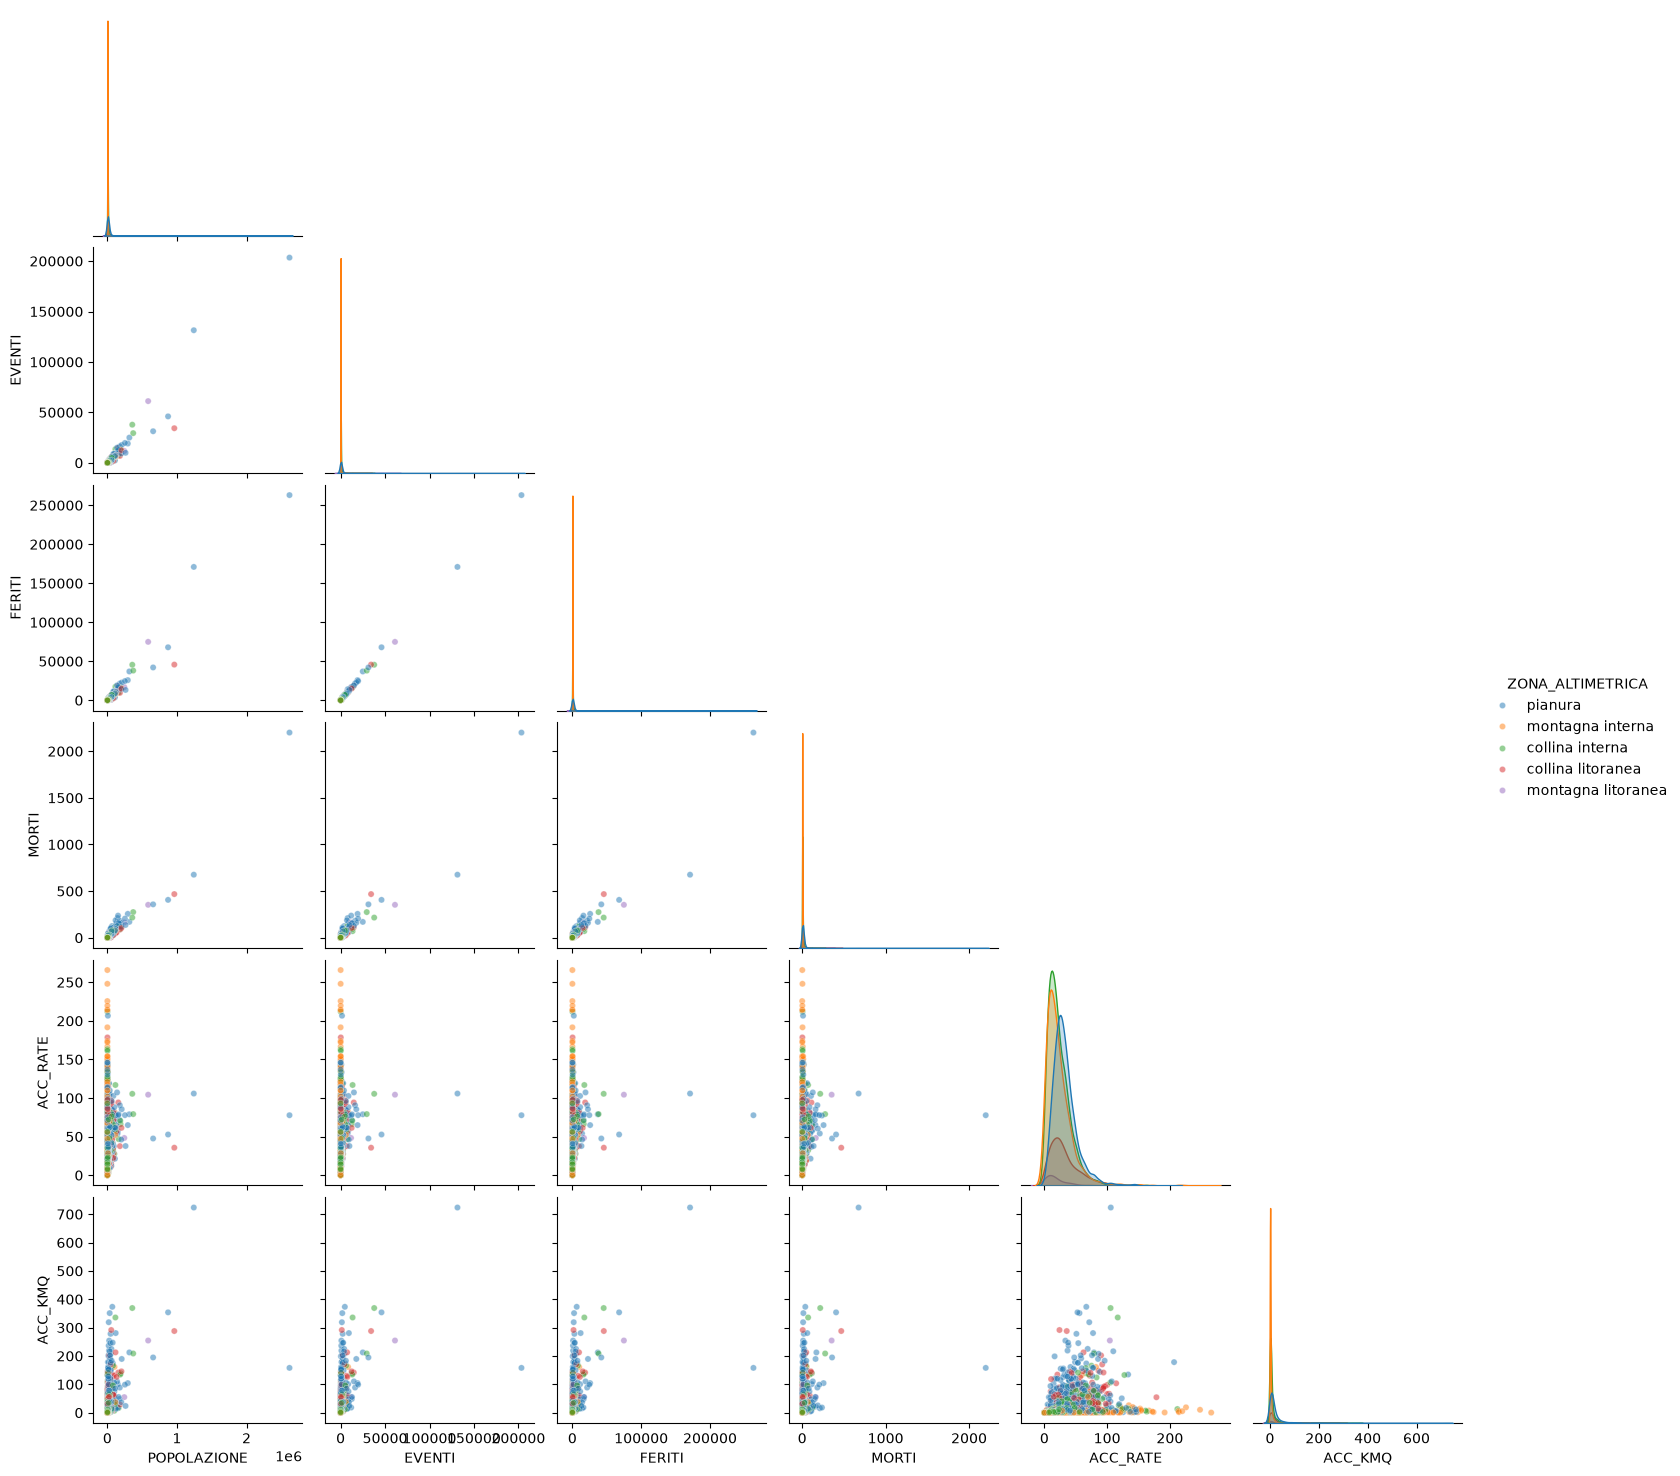

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

colonne_scelte = [
    'POPOLAZIONE',
    'EVENTI',
    'FERITI',
    'MORTI',
    'ACC_RATE',
    'ACC_KMQ',
]

sns.pairplot(
    incidenti_totale[
        colonne_scelte + ['ZONA_ALTIMETRICA']
    ],  # Aggiungiamo la categoria per i colori
    hue='ZONA_ALTIMETRICA',  # Colora i punti in base alla montagna/collina/pianura
    diag_kind='kde',
    corner=True,  # Taglia la metà vuota/ripetuta
    plot_kws={
        'alpha': 0.5,
        's': 20,
    },  # Trasparenza (0.5) e dimensione ridotta dei pallini (20)
)

plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'incidenti_totale.csv'